# MetroFlow: EDA and time-series diagnostics

**Executed submission notebook.** Data: official NY Open Data MTA hourly ridership, station complex 611. The prepared series contains one hourly entry total per timestamp.

In [1]:
# Load the prepared station-level hourly series
df = pd.read_csv('../data/processed/mta_hourly_station_611_clean.csv', parse_dates=['timestamp'])
df.shape


Rows: 15,840
Coverage: 2025-01-01T00:00:00 to 2026-10-22T23:00:00
Imputed DST hour: 1


## Data exploration and correction audit

The modelling table has one timestamp per hour after aggregation across fare/payment categories. Quality checks found no duplicate timestamps or negative ridership. One daylight-saving skipped hour was repaired using comparable historical observations and retained with an audit flag.

**Distribution:** mean hourly entries = 5,556.69; median = 5,551.00; P90 = 10,508.10; range = 7–19,302.

## Trend and demand volume

Daily demand is not flat; it has recurring weekday patterns. The daily trend is used for demand monitoring rather than as evidence of real-time crowd density.

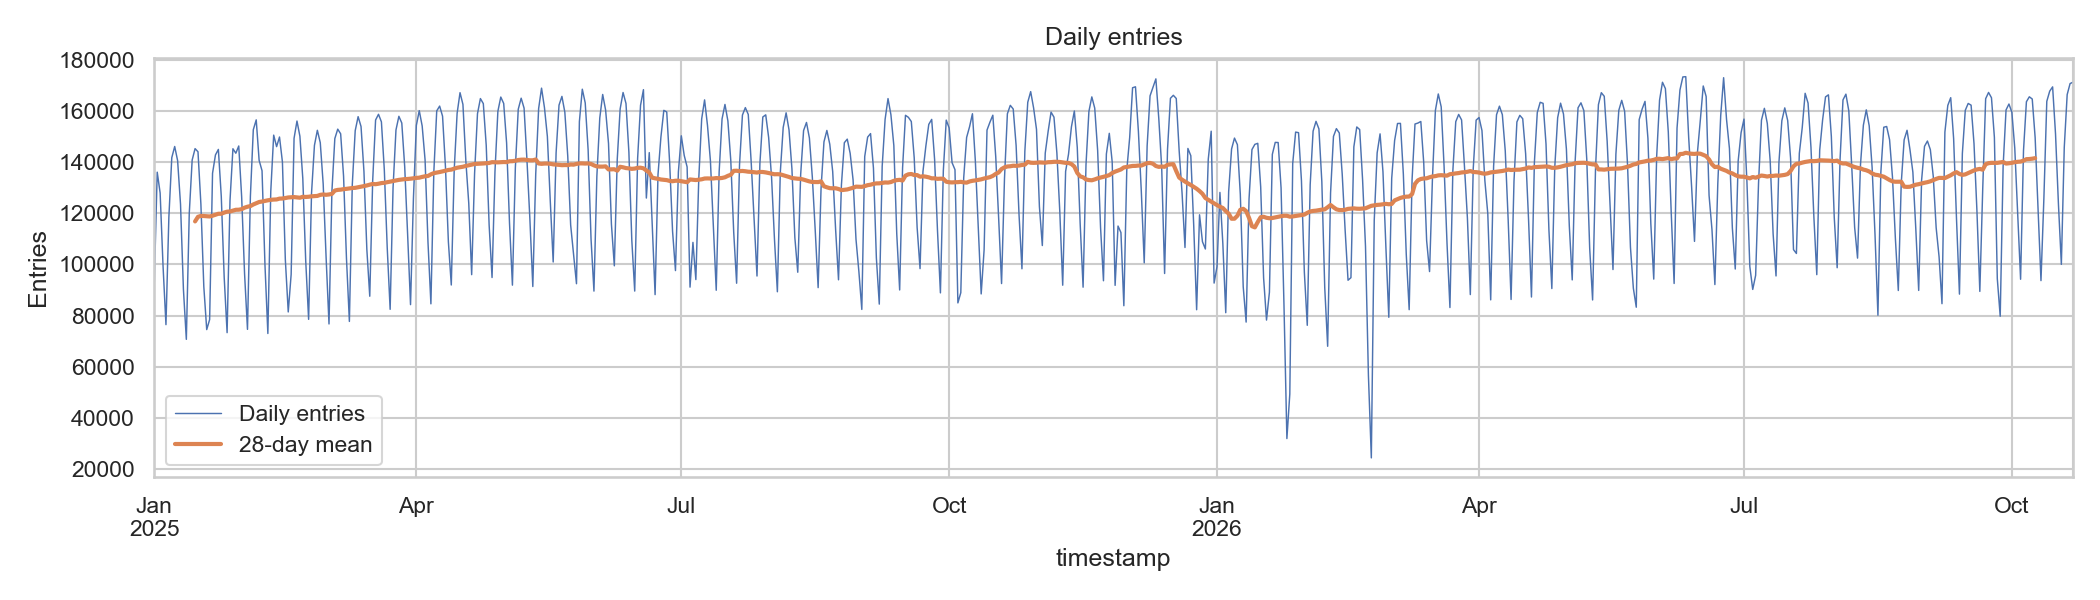

Mean daily entries: 133,360.63


In [1]:
# Daily aggregation and rolling 28-day trend
daily = df.set_index('timestamp').ridership.resample('D').sum()
daily.mean()


## Intraday and weekly seasonality

The heatmap reveals the operational demand profile. Peak hours occur in the late afternoon, which supports hour-aware forecasting and staffing alerts.

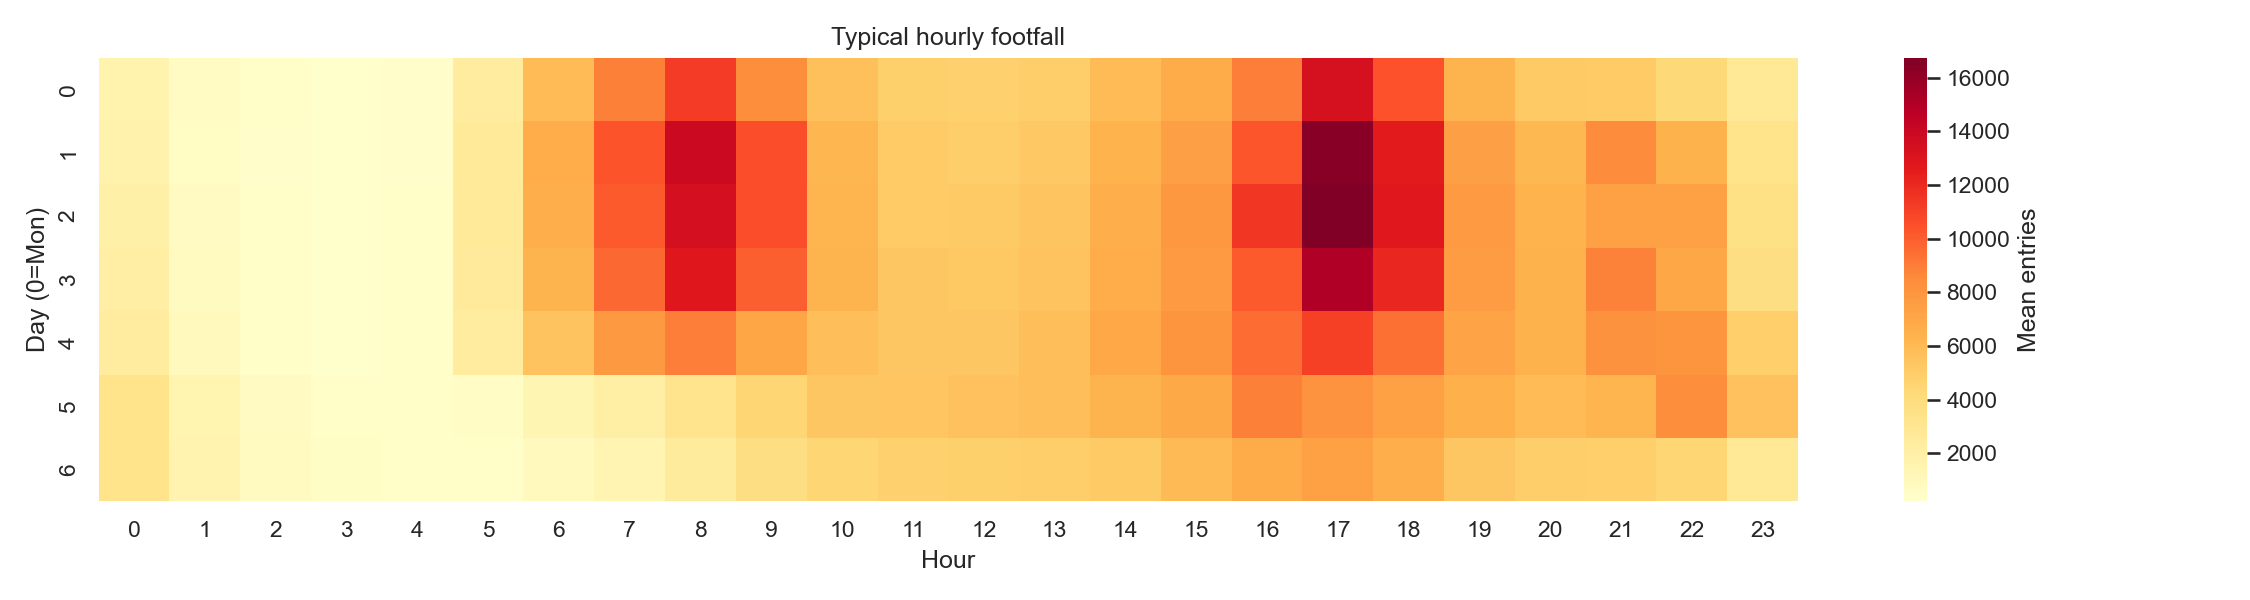

Peak hour by weekday (0=Monday):
{
  "0": 17,
  "1": 17,
  "2": 17,
  "3": 17,
  "4": 17,
  "5": 16,
  "6": 17
}


In [1]:
# Mean ridership by weekday and hour
heatmap = df.pivot_table(index='day_of_week', columns='hour', values='ridership', aggfunc='mean')


## Weekday versus weekend profile

Separating weekday and weekend demand makes the alert threshold fairer: a weekend hour is not compared with a commuter-period weekday hour.

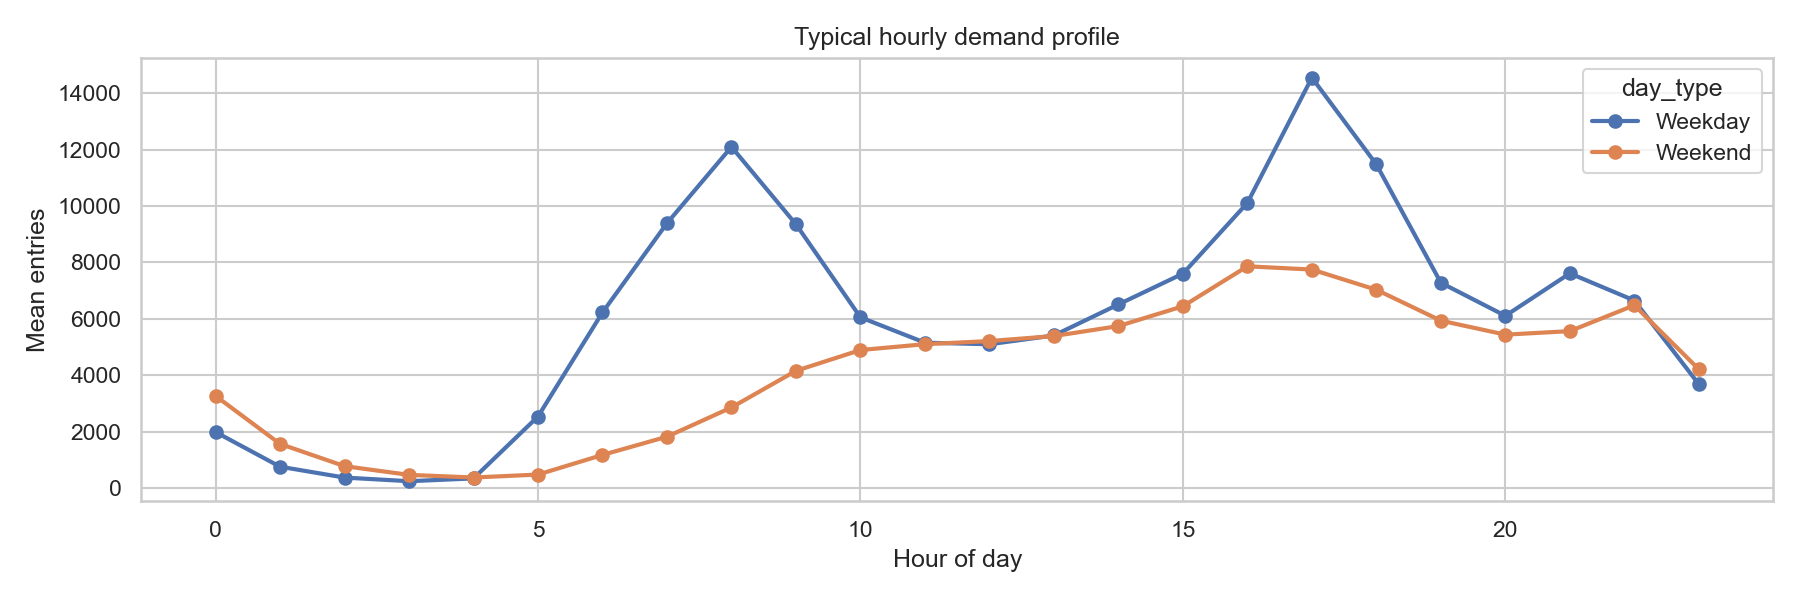

In [1]:
# Compare typical hourly weekday and weekend demand
profile = df.groupby(['is_weekend', 'hour']).ridership.mean()


## Autocorrelation evidence

Autocorrelation at 24 hours and 168 hours is very high. This justifies comparing a weekly seasonal-naive baseline and calendar-aware forecasting models.

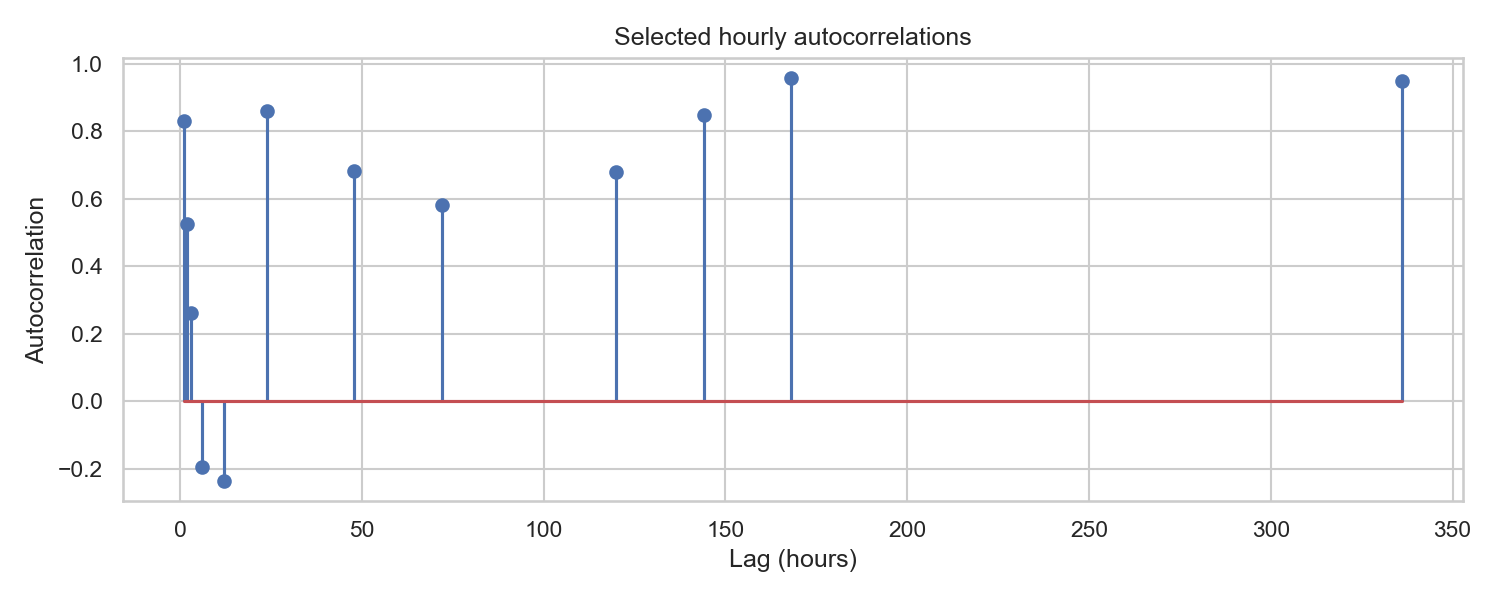

ACF(24h) = 0.8614
ACF(168h) = 0.959


In [1]:
# Selected autocorrelations
{lag: df.ridership.autocorr(int(lag)) for lag in [1, 24, 168]}


## Historical anomaly review

This review flags an observation only when it lies outside the historical 5th–95th percentile for the same hour and weekday/weekend type. It is a prompt for investigation, not proof of an operational incident.

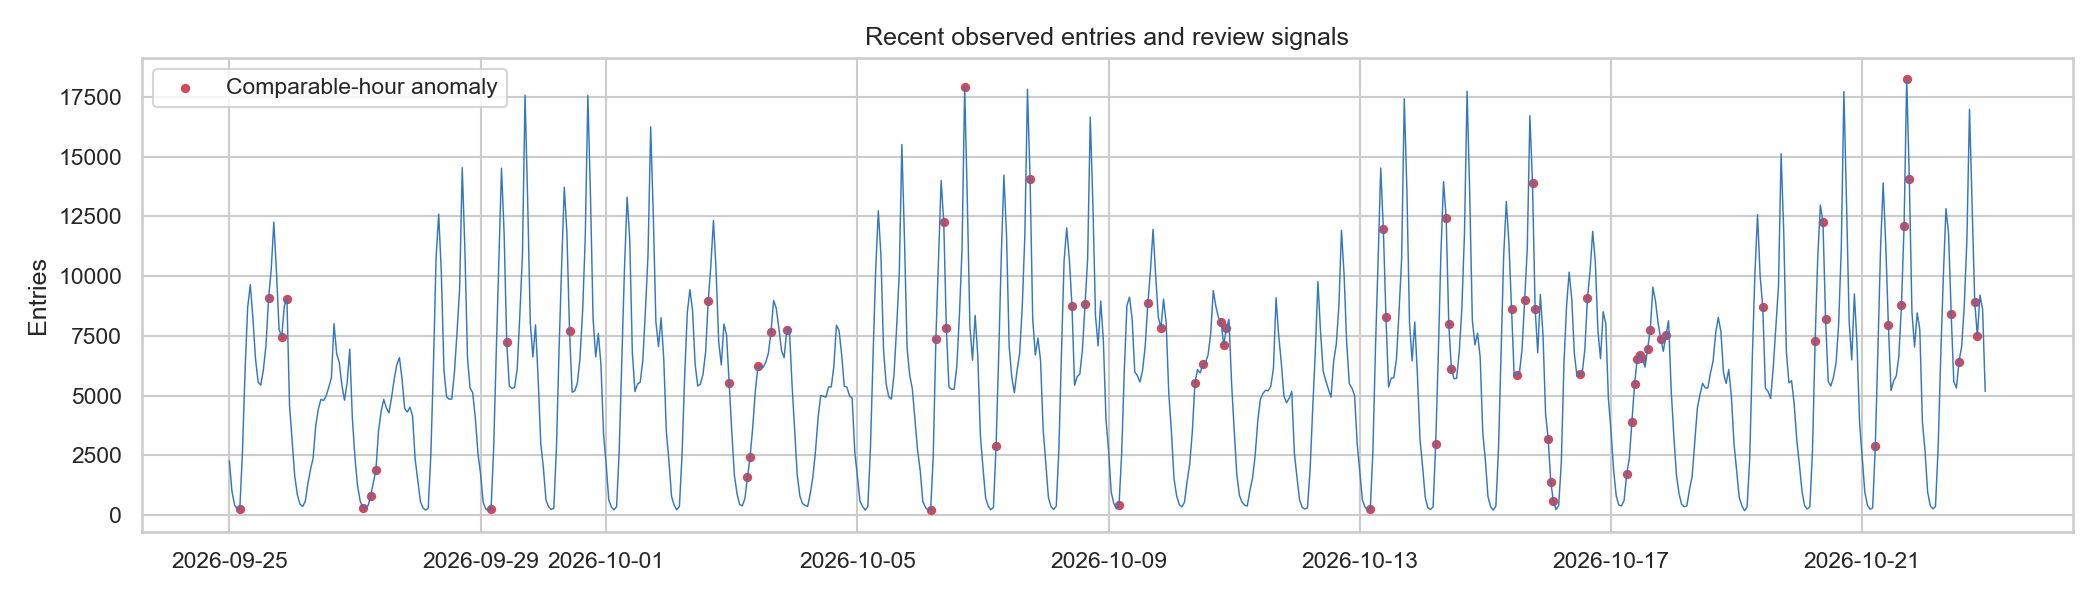

Comparable-hour anomaly candidates in full history: 1,627


In [1]:
# Comparable-hour anomaly screen for the last 28 days
anomalies = compare_against_hour_day_bounds(df)


## EDA conclusion

1. The series has strong daily and weekly recurrence.
2. A weekly seasonal-naive baseline is mandatory because it is a meaningful benchmark.
3. Calendar features (hour, weekday/weekend, and trend) are appropriate for the production model.
4. The daylight-saving gap was explicitly documented and imputed once; it is not silently removed.

STL decomposition, ADF, and PACF code remains in the original notebook cells and will be rerun once `statsmodels` is available locally.